### Initial Imports 

In [21]:
import rebound
import numpy as np
import matplotlib.pyplot as plt

### The delta_P function

From conservation of momentum, we have

$ m_D v_{i,D} + m_s v_{i,s} = m_D v_{f,D} + \gamma $ 

Where $\gamma$ contains all the extra parameters that we don't know (e.g. ejecta mass, ejecta velocity).

Rearranging gives us 

$ m_D v_{f,D}  - m_D v_{i,D} = m_s v_{i,s} - \gamma $ 

$ \Delta v = v_{f,D}  - v_{i,D} = (m_s v_{i,s} - \gamma) / m_D $ 

In [22]:
def delta_P(gamma, P0): 
    """
    Function that takes a value for gamma + the initial period of the Didymos-Dimorphos system (in seconds)
    Then runs the simulation. 
    Returns the difference in the final period in the simulation with the observed post-impact period (in hours). 
    """
    # Setting up the simulation
    sim = rebound.Simulation()
    sim.integrator = "whfast"
    sim.G = 6.6743e-11 # m^3 / kg s^2
    sim.add(m=5.2e11) # Didymos
    sim.add(m=4.3e9, P=P0, e=0) # Dimorphos 
    sim.dt = P0 / 1000 
    sim.move_to_com() 

    # DART impact
    ps = sim.particles
    m_s = 579.4 # kg 
    v_is = 6.1449e3 # m/s 
    m_D = 4.3e9 # kg
    dv = (m_s * v_is - gamma) / m_D
    ps[1].vy -= dv

    # Running the simulation 
    Nout = 1000
    period_values = np.zeros(Nout) 
    times = np.linspace(0, 10 * P0, Nout)
    
    for i, time in enumerate(times):
        sim.integrate(time, exact_finish_time=0) 
        period_values[i] = sim.particles[1].P

    return (period_values[-1] / (60 * 60)) - 11.3676

### Results for different values of gamma

Gamma values: [ -5000000.  -5500000.  -6000000.  -6500000.  -7000000.  -7500000.
  -8000000.  -8500000.  -9000000.  -9500000. -10000000.]
Gamma for nominal value = -8486959.177039754
Gamma for upper value = -8487894.01769074
Gamma for lower value = -8486024.327306736


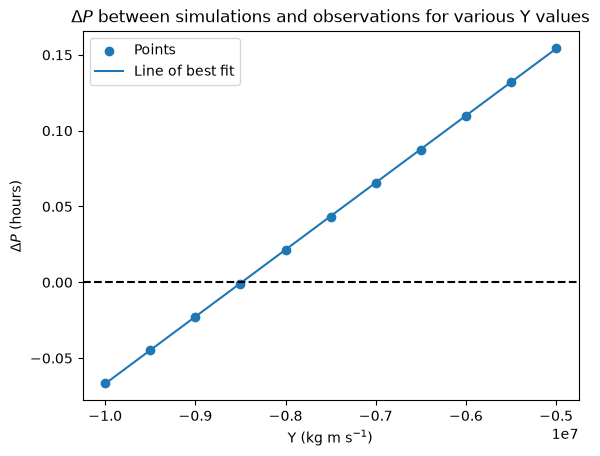

In [23]:
start = -5e6
end = -10e6
N = 11

gamma_values = np.linspace(start, end, N)
print("Gamma values:", gamma_values)

# ------------------------------------------------------------------------------------------------------------------------
# Initial period: Nominal value 

delta_P_values = np.zeros(N)

for i in range(N):
    delta_P_values[i] = delta_P(gamma_values[i], 11.921473 * 60 * 60)

plt.scatter(gamma_values, delta_P_values, label='Points')

a, b = np.polyfit(gamma_values, delta_P_values, 1)
plt.plot(gamma_values, a * gamma_values + b, label='Line of best fit') 

gamma_nominal = -b/a
print('Gamma for nominal value =', gamma_nominal)

# ------------------------------------------------------------------------------------------------------------------------
# Initial period: Upper Bound 

delta_P_values = np.zeros(N)

for i in range(N):
    delta_P_values[i] = delta_P(gamma_values[i], (11.921473+0.000044) * 60 * 60)

#plt.scatter(gamma_values, delta_P_values)

a, b = np.polyfit(gamma_values, delta_P_values, 1)
#plt.plot(gamma_values, a * gamma_values + b, label='Upper Bound') 

gamma_upper = -b/a
print('Gamma for upper value =', gamma_upper)

# ------------------------------------------------------------------------------------------------------------------------
# Initial period: Lower Bound 

delta_P_values = np.zeros(N)

for i in range(N):
    delta_P_values[i] = delta_P(gamma_values[i], (11.921473-0.000044) * 60 * 60)

#plt.scatter(gamma_values, delta_P_values)

a, b = np.polyfit(gamma_values, delta_P_values, 1)
#plt.plot(gamma_values, a * gamma_values + b, label='Lower Bound') 

gamma_lower = -b/a
print('Gamma for lower value =', gamma_lower)

# ------------------------------------------------------------------------------------------------------------------------

plt.axhline(0, color="black", linestyle="--")
plt.xlabel(r"$\Upsilon$ (kg m s$^{-1}$)")
plt.ylabel(r"$\Delta P$ (hours)")
plt.title(r"$\Delta P$ between simulations and observations for various $\Upsilon$ values")
plt.legend()
plt.show()

In [24]:
print(gamma_nominal - gamma_lower)
print(gamma_upper - gamma_nominal)

-934.849733017385
-934.8406509868801
